# Phase 14 — TCI Baseline Comparison

**Notebook:** `13_baseline_comparison.ipynb`

## Why this notebook exists

This project's central claim is that a graph-relational, physics-informed
model (the `DualBranchGAT`) improves on the existing single-number
**Thermal Change Index (TCI)** biomarker. That claim has never been
directly tested.

This notebook:

1. Builds simple TCI-only baseline classifiers (logistic regression and
   AdaBoost, on the worse-affected foot's TCI and on both feet's TCI).
2. Evaluates every baseline through the **exact same 5 patient-level
   folds** used for the `DualBranchGAT` in Phase 13
   (`12_cross_validation.ipynb`), so the comparison is paired and fair.
3. Runs a **DeLong test** to check whether the `DualBranchGAT`'s ROC
   curve is statistically better than the best TCI baseline's — not just
   numerically higher.

This notebook re-reads only two files, both of which are the complete
source of truth needed:

- `data/processed/subject_metadata.csv` (167 subjects, TCI + Group columns)
- `results/cv_pooled_predictions.csv` (Phase 13's pooled out-of-fold
  `DualBranchGAT` predictions, including the `fold` column that is the
  only source of truth for fold membership)

No raw Excel file and no raw dataset directory are touched here.


## Section 1 — Setup

Import libraries, fix the random seed, load the two source-of-truth
files, and make sure the `results/` output folder exists.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    f1_score,
    accuracy_score,
    roc_curve,
)

print("=== SECTION 1: Setup ===")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

METADATA_PATH = Path("data/processed/subject_metadata.csv")
CV_PRED_PATH = Path("results/cv_pooled_predictions.csv")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Project color convention (Control = blue, DM = orange), reused for the
# DualBranchGAT (DM color) vs. baseline (distinct blue) ROC overlay later.
DM_COLOR = "#ff7f0e"
BASELINE_COLOR = "#1f77b4"

metadata_df = pd.read_csv(METADATA_PATH)
cv_pooled_df = pd.read_csv(CV_PRED_PATH)

print(f"metadata_df shape: {metadata_df.shape}")
print(f"cv_pooled_df shape: {cv_pooled_df.shape}")
print(f"results/ directory ready at: {RESULTS_DIR.resolve()}")


=== SECTION 1: Setup ===
metadata_df shape: (167, 19)
cv_pooled_df shape: (167, 6)
results/ directory ready at: C:\workstation\3RD YEAR\Diabetic_Foot\results


## Section 2 — Reproduce the exact same 5 folds as Phase 13

`results/cv_pooled_predictions.csv`'s `fold` column is the **only**
source of truth for fold membership. To reproduce it exactly (not
regenerate an independent split), we:

1. Read `subject_metadata.csv` fresh, in its original row order (no
   sorting or reordering).
2. Take `subject_ids_all` and `groups_all` from that exact row order.
3. Run `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` on
   those arrays and enumerate the folds in order (fold 0 → fold 4).

For each fold, the freshly computed test-set subject IDs are compared
against `cv_pooled_predictions.csv`'s subjects for that fold number.
**If any fold fails to match exactly, we stop here** — training
baselines on mismatched folds would silently invalidate the whole
comparison.


In [2]:
print("=== SECTION 2: Reproducing Phase 13's Exact 5 Folds ===")

subject_ids_all = metadata_df["Subject"].values
groups_all = metadata_df["Group"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
fold_splits = list(skf.split(subject_ids_all, groups_all))

all_folds_pass = True
for fold_idx, (train_idx, test_idx) in enumerate(fold_splits):
    fresh_test_subjects = set(subject_ids_all[test_idx])
    truth_test_subjects = set(
        cv_pooled_df.loc[cv_pooled_df["fold"] == fold_idx, "subject_id"]
    )
    fold_match = fresh_test_subjects == truth_test_subjects
    all_folds_pass = all_folds_pass and fold_match
    status = "PASS" if fold_match else "FAIL"
    print(f"  Fold {fold_idx}: {status}  (n_test={len(fresh_test_subjects)})")

print()
if all_folds_pass:
    print("OVERALL FOLD-MATCH VALIDATION: PASS")
else:
    print("!" * 70)
    print("OVERALL FOLD-MATCH VALIDATION: FAIL")
    print("Freshly computed folds do NOT match cv_pooled_predictions.csv.")
    print("Stopping -- refusing to train baselines on mismatched folds.")
    print("!" * 70)

assert all_folds_pass, "Fold-match validation failed -- see printed warning above."


=== SECTION 2: Reproducing Phase 13's Exact 5 Folds ===
  Fold 0: PASS  (n_test=34)
  Fold 1: PASS  (n_test=34)
  Fold 2: PASS  (n_test=33)
  Fold 3: PASS  (n_test=33)
  Fold 4: PASS  (n_test=33)

OVERALL FOLD-MATCH VALIDATION: PASS


## Section 3 — Feature prep

Two TCI feature versions per subject, built from `subject_metadata.csv`'s
existing `RIGHT_TCI` / `LEFT_TCI` columns (no missing values in either):

- **`worse_foot_tci`** — `max(RIGHT_TCI, LEFT_TCI)`, the clinical
  convention of using the more-affected foot. A single feature.
- **`both_feet_tci`** — `[RIGHT_TCI, LEFT_TCI]`, two features.

Labels: `y = 1` if `Group == "DM"` else `0` — the same convention used
for the `DualBranchGAT`.


In [3]:
print("=== SECTION 3: Feature Prep ===")

metadata_df["worse_foot_tci"] = metadata_df[["RIGHT_TCI", "LEFT_TCI"]].max(axis=1)

X_worse_foot = metadata_df[["worse_foot_tci"]].values
X_both_feet = metadata_df[["RIGHT_TCI", "LEFT_TCI"]].values
y_all = (metadata_df["Group"] == "DM").astype(int).values

print(f"worse_foot_tci feature matrix shape: {X_worse_foot.shape}")
print(f"both_feet_tci feature matrix shape:  {X_both_feet.shape}")
print(f"label vector shape: {y_all.shape}, positive (DM) rate: {y_all.mean():.3f}")


=== SECTION 3: Feature Prep ===
worse_foot_tci feature matrix shape: (167, 1)
both_feet_tci feature matrix shape:  (167, 2)
label vector shape: (167,), positive (DM) rate: 0.731


## Section 4 — Train baselines per fold

For each of the 5 folds (using the exact `test_idx` sets validated in
Section 2), fit on that fold's non-test subjects and predict probabilities
on that fold's test subjects, for four baseline variants:

| variant | model | features |
|---|---|---|
| `LR_worse_foot_tci` | `LogisticRegression(class_weight='balanced')` | worse-foot TCI |
| `LR_both_feet_tci` | `LogisticRegression(class_weight='balanced')` | both feet's TCI |
| `AdaBoost_worse_foot_tci` | `AdaBoostClassifier(random_state=42)` | worse-foot TCI |
| `AdaBoost_both_feet_tci` | `AdaBoostClassifier(random_state=42)` | both feet's TCI |

For each variant we build one pooled out-of-fold predicted-probability
array covering all 167 subjects (each subject's prediction coming from
whichever fold held it out) — the same pattern Phase 13 used for the
`DualBranchGAT`. We also cache each fold's **training** probabilities
(needed for Section 5's per-fold threshold selection).


In [4]:
print("=== SECTION 4: Training Baselines Per Fold ===")

VARIANTS = {
    "LR_worse_foot_tci": (LogisticRegression, dict(class_weight="balanced"), X_worse_foot),
    "LR_both_feet_tci": (LogisticRegression, dict(class_weight="balanced"), X_both_feet),
    "AdaBoost_worse_foot_tci": (AdaBoostClassifier, dict(random_state=RANDOM_SEED), X_worse_foot),
    "AdaBoost_both_feet_tci": (AdaBoostClassifier, dict(random_state=RANDOM_SEED), X_both_feet),
}

n_subjects = len(subject_ids_all)
pooled_prob = {name: np.full(n_subjects, np.nan) for name in VARIANTS}
# fold_train_cache[name][fold_idx] = (train_probabilities, y_train) -- for Section 5
fold_train_cache = {name: {} for name in VARIANTS}

for fold_idx, (train_idx, test_idx) in enumerate(fold_splits):
    y_train = y_all[train_idx]
    for name, (Model, kwargs, X) in VARIANTS.items():
        clf = Model(**kwargs)
        clf.fit(X[train_idx], y_train)

        train_prob = clf.predict_proba(X[train_idx])[:, 1]
        test_prob = clf.predict_proba(X[test_idx])[:, 1]

        pooled_prob[name][test_idx] = test_prob
        fold_train_cache[name][fold_idx] = (train_prob, y_train)

    print(f"  Fold {fold_idx}: trained all 4 variants "
          f"(train n={len(train_idx)}, test n={len(test_idx)})")

for name in VARIANTS:
    n_missing = int(np.isnan(pooled_prob[name]).sum())
    print(f"{name}: pooled predictions built for all {n_subjects - n_missing}/{n_subjects} subjects")
    assert n_missing == 0, f"{name} is missing out-of-fold predictions for {n_missing} subjects"


=== SECTION 4: Training Baselines Per Fold ===


  Fold 0: trained all 4 variants (train n=133, test n=34)
  Fold 1: trained all 4 variants (train n=133, test n=34)
  Fold 2: trained all 4 variants (train n=134, test n=33)
  Fold 3: trained all 4 variants (train n=134, test n=33)
  Fold 4: trained all 4 variants (train n=134, test n=33)
LR_worse_foot_tci: pooled predictions built for all 167/167 subjects
LR_both_feet_tci: pooled predictions built for all 167/167 subjects
AdaBoost_worse_foot_tci: pooled predictions built for all 167/167 subjects
AdaBoost_both_feet_tci: pooled predictions built for all 167/167 subjects


## Section 5 — Threshold selection (Youden's J, per fold)

For each baseline variant, per fold, we compute that fold's own
Youden's-J-optimal threshold from that fold's **training** subjects'
predicted probabilities (in-sample, since these are simple models with
no separate validation set) and apply it to that fold's **test**
subjects — the same threshold-per-fold philosophy Phase 13 used for the
`DualBranchGAT`.


In [5]:
print("=== SECTION 5: Threshold Selection (Youden's J, Per Fold) ===")

pooled_pred = {name: np.full(n_subjects, -1, dtype=int) for name in VARIANTS}
fold_thresholds = {name: {} for name in VARIANTS}

for fold_idx, (train_idx, test_idx) in enumerate(fold_splits):
    for name in VARIANTS:
        train_prob, y_train = fold_train_cache[name][fold_idx]
        fpr, tpr, thresh = roc_curve(y_train, train_prob)
        youden_j = tpr - fpr
        best_thresh = thresh[np.argmax(youden_j)]
        fold_thresholds[name][fold_idx] = best_thresh

        test_prob_fold = pooled_prob[name][test_idx]
        pooled_pred[name][test_idx] = (test_prob_fold >= best_thresh).astype(int)

for name in VARIANTS:
    thresholds_str = ", ".join(
        f"fold{f}={fold_thresholds[name][f]:.3f}" for f in range(5)
    )
    print(f"{name}: {thresholds_str}")

for name in VARIANTS:
    n_unset = int((pooled_pred[name] == -1).sum())
    assert n_unset == 0, f"{name} has {n_unset} subjects with no hard prediction"
print()
print("All variants have a hard prediction for all 167 subjects.")


=== SECTION 5: Threshold Selection (Youden's J, Per Fold) ===
LR_worse_foot_tci: fold0=0.550, fold1=0.575, fold2=0.621, fold3=0.575, fold4=0.497
LR_both_feet_tci: fold0=0.731, fold1=0.762, fold2=0.415, fold3=0.568, fold4=0.771
AdaBoost_worse_foot_tci: fold0=0.540, fold1=0.557, fold2=0.547, fold3=0.529, fold4=0.559
AdaBoost_both_feet_tci: fold0=0.521, fold1=0.529, fold2=0.562, fold3=0.526, fold4=0.551

All variants have a hard prediction for all 167 subjects.


## Section 6 — Aggregate metrics

For each of the 4 baseline variants **and** for the `DualBranchGAT`'s
existing `mc_mean_prob` column (from `cv_pooled_predictions.csv`, at its
existing `pred_label_optimal`), compute pooled (167-subject) ROC-AUC,
balanced accuracy, F1, and accuracy. One comparison table, all 5 models
as rows, sorted by ROC-AUC descending.


In [6]:
print("=== SECTION 6: Aggregate Metrics ===")

comparison_rows = []
for name in VARIANTS:
    p = pooled_prob[name]
    pred = pooled_pred[name]
    comparison_rows.append(dict(
        model=name,
        roc_auc=roc_auc_score(y_all, p),
        balanced_accuracy=balanced_accuracy_score(y_all, pred),
        f1=f1_score(y_all, pred),
        accuracy=accuracy_score(y_all, pred),
    ))

# DualBranchGAT's existing pooled out-of-fold predictions
gat_prob_by_subject = dict(zip(cv_pooled_df["subject_id"], cv_pooled_df["mc_mean_prob"]))
gat_pred_by_subject = dict(zip(cv_pooled_df["subject_id"], cv_pooled_df["pred_label_optimal"]))
gat_prob = np.array([gat_prob_by_subject[s] for s in subject_ids_all])
gat_pred = np.array([gat_pred_by_subject[s] for s in subject_ids_all])

comparison_rows.append(dict(
    model="DualBranchGAT",
    roc_auc=roc_auc_score(y_all, gat_prob),
    balanced_accuracy=balanced_accuracy_score(y_all, gat_pred),
    f1=f1_score(y_all, gat_pred),
    accuracy=accuracy_score(y_all, gat_pred),
))

comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

print(comparison_df.to_string(index=False))

best_baseline_name = comparison_df.loc[comparison_df["model"] != "DualBranchGAT", "model"].iloc[0]
print()
print(f"Best-performing TCI baseline by pooled ROC-AUC: {best_baseline_name}")


=== SECTION 6: Aggregate Metrics ===
                  model  roc_auc  balanced_accuracy       f1  accuracy
          DualBranchGAT 0.877778           0.756648 0.868852  0.808383
      LR_worse_foot_tci 0.858834           0.785792 0.803738  0.748503
 AdaBoost_both_feet_tci 0.837523           0.810383 0.836364  0.784431
       LR_both_feet_tci 0.828415           0.724317 0.713568  0.658683
AdaBoost_worse_foot_tci 0.825137           0.748361 0.787037  0.724551

Best-performing TCI baseline by pooled ROC-AUC: LR_worse_foot_tci


## Section 7 — DeLong test

A numerically higher AUC is not the same as a *statistically significant*
improvement. The DeLong test compares two correlated (paired, same-subject)
ROC-AUCs and tests whether their difference is significant, using the
standard DeLong covariance-based approach (Sun & Xu, 2014's fast
$O(N\log N)$ formulation). Implemented directly with numpy — no external
`delong-test` package — so there's no new dependency.

We run it comparing the `DualBranchGAT`'s pooled `mc_mean_prob` against
**each** of the 4 baseline variants' pooled probabilities, all on the
same 167 subjects, correctly paired by `subject_id`.


In [7]:
print("=== SECTION 7: DeLong Test ===")


def _compute_midrank(x):
    """Midranks of x, correctly handling ties (needed by fast DeLong)."""
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2


def _fast_delong(predictions_sorted_transposed, label_1_count):
    """Core DeLong covariance computation (Sun & Xu, 2014).

    predictions_sorted_transposed: (k, N) array, k=number of models being
    compared, N=number of subjects, with the first `label_1_count` columns
    being the positive-class (DM) subjects.
    """
    m = label_1_count
    n = predictions_sorted_transposed.shape[1] - m
    k = predictions_sorted_transposed.shape[0]

    positive_examples = predictions_sorted_transposed[:, :m]
    negative_examples = predictions_sorted_transposed[:, m:]

    tx = np.empty([k, m], dtype=float)
    ty = np.empty([k, n], dtype=float)
    tz = np.empty([k, m + n], dtype=float)
    for r in range(k):
        tx[r, :] = _compute_midrank(positive_examples[r, :])
        ty[r, :] = _compute_midrank(negative_examples[r, :])
        tz[r, :] = _compute_midrank(predictions_sorted_transposed[r, :])

    aucs = tz[:, :m].sum(axis=1) / (m * n) - (m + 1.0) / (2.0 * n)

    v01 = (tz[:, :m] - tx[:, :]) / n
    v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m

    sx = np.cov(v01)
    sy = np.cov(v10)
    delongcov = sx / m + sy / n
    return aucs, delongcov


def delong_roc_test(y_true, prob_a, prob_b):
    """Paired DeLong test comparing two models' AUCs on the SAME subjects.

    Returns AUC of each model, their difference, the DeLong z-statistic,
    and the corresponding two-sided p-value.
    """
    order = np.argsort(-y_true, kind="stable")
    y_sorted = y_true[order]
    m = int(np.sum(y_sorted == 1))

    preds = np.vstack([prob_a[order], prob_b[order]])
    aucs, delongcov = _fast_delong(preds, m)

    auc_a, auc_b = float(aucs[0]), float(aucs[1])
    diff = auc_a - auc_b
    var = delongcov[0, 0] + delongcov[1, 1] - 2 * delongcov[0, 1]
    var = max(var, 1e-12)  # numerical floor
    z = diff / np.sqrt(var)
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    return dict(auc_gat=auc_a, auc_baseline=auc_b, auc_diff=diff, z=z, p_value=p_value)


delong_results = {}
for name in VARIANTS:
    result = delong_roc_test(y_all.astype(float), gat_prob, pooled_prob[name])
    delong_results[name] = result
    print(f"--- DualBranchGAT vs. {name} ---")
    print(f"  AUC_gat      = {result['auc_gat']:.4f}")
    print(f"  AUC_baseline = {result['auc_baseline']:.4f}")
    print(f"  AUC diff     = {result['auc_diff']:+.4f}")
    print(f"  z-statistic  = {result['z']:.4f}")
    print(f"  p-value      = {result['p_value']:.4f}")
    print()

# Sanity check: DeLong's own AUC computation should agree with sklearn's
# roc_auc_score for both series in every comparison (confirms the
# midrank/AUC machinery above is correct, not just the covariance step).
print("Sanity check -- DeLong-computed AUC vs. sklearn roc_auc_score:")
sk_gat_auc = roc_auc_score(y_all, gat_prob)
for name in VARIANTS:
    sk_base_auc = roc_auc_score(y_all, pooled_prob[name])
    match = (
        np.isclose(delong_results[name]["auc_gat"], sk_gat_auc)
        and np.isclose(delong_results[name]["auc_baseline"], sk_base_auc)
    )
    print(f"  {name}: {'PASS' if match else 'FAIL'}")


=== SECTION 7: DeLong Test ===
--- DualBranchGAT vs. LR_worse_foot_tci ---
  AUC_gat      = 0.8778
  AUC_baseline = 0.8588
  AUC diff     = +0.0189
  z-statistic  = 0.7429
  p-value      = 0.4575

--- DualBranchGAT vs. LR_both_feet_tci ---
  AUC_gat      = 0.8778
  AUC_baseline = 0.8284
  AUC diff     = +0.0494
  z-statistic  = 1.8644
  p-value      = 0.0623

--- DualBranchGAT vs. AdaBoost_worse_foot_tci ---
  AUC_gat      = 0.8778
  AUC_baseline = 0.8251
  AUC diff     = +0.0526
  z-statistic  = 1.6684
  p-value      = 0.0952

--- DualBranchGAT vs. AdaBoost_both_feet_tci ---
  AUC_gat      = 0.8778
  AUC_baseline = 0.8375
  AUC diff     = +0.0403
  z-statistic  = 1.2751
  p-value      = 0.2023

Sanity check -- DeLong-computed AUC vs. sklearn roc_auc_score:
  LR_worse_foot_tci: PASS
  LR_both_feet_tci: PASS
  AdaBoost_worse_foot_tci: PASS
  AdaBoost_both_feet_tci: PASS


## Section 8 — Plot

Overlay pooled (167-subject) ROC curves for the `DualBranchGAT` and the
single best-performing TCI baseline variant, with both AUCs and that
comparison's DeLong p-value annotated on the plot.


=== SECTION 8: ROC Curve Overlay ===


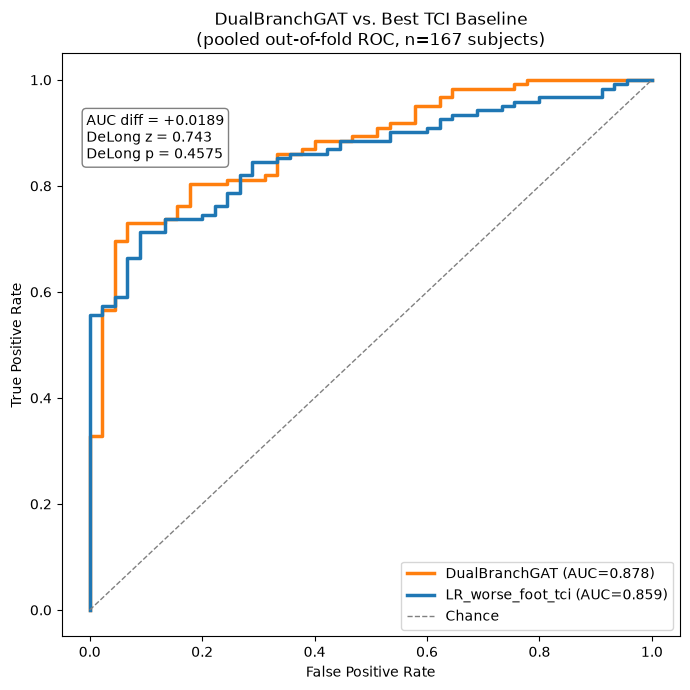

Best baseline plotted against DualBranchGAT: LR_worse_foot_tci


In [8]:
print("=== SECTION 8: ROC Curve Overlay ===")

best_result = delong_results[best_baseline_name]

fpr_gat, tpr_gat, _ = roc_curve(y_all, gat_prob)
fpr_base, tpr_base, _ = roc_curve(y_all, pooled_prob[best_baseline_name])

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(
    fpr_gat, tpr_gat,
    color=DM_COLOR, linewidth=2.5,
    label=f"DualBranchGAT (AUC={best_result['auc_gat']:.3f})",
)
ax.plot(
    fpr_base, tpr_base,
    color=BASELINE_COLOR, linewidth=2.5,
    label=f"{best_baseline_name} (AUC={best_result['auc_baseline']:.3f})",
)
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="Chance")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("DualBranchGAT vs. Best TCI Baseline\n(pooled out-of-fold ROC, n=167 subjects)")
ax.legend(loc="lower right")

annotation = (
    f"AUC diff = {best_result['auc_diff']:+.4f}\n"
    f"DeLong z = {best_result['z']:.3f}\n"
    f"DeLong p = {best_result['p_value']:.4f}"
)
ax.text(
    0.04, 0.82, annotation,
    transform=ax.transAxes, fontsize=10,
    bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray"),
)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "baseline_comparison_roc.png", dpi=150)
plt.show()

print(f"Best baseline plotted against DualBranchGAT: {best_baseline_name}")


## Section 9 — Qualitative summary

*(Fill this in after reviewing the actual printed numbers above — the
cell below states it programmatically from the real Section 6/7 results
so the written conclusion always tracks whatever this run actually
produced, and is never rounded up.)*


In [9]:
print("=== SECTION 9: Qualitative Summary (data-driven) ===")

alpha = 0.05
gat_auc = comparison_df.loc[comparison_df["model"] == "DualBranchGAT", "roc_auc"].iloc[0]
best_baseline_auc = comparison_df.loc[comparison_df["model"] == best_baseline_name, "roc_auc"].iloc[0]
best_p = best_result["p_value"]
direction = "higher" if best_result["auc_diff"] > 0 else "lower or equal"
significant = best_p < alpha

summary_lines = [
    f"DualBranchGAT pooled ROC-AUC:                {gat_auc:.4f}",
    f"Best TCI baseline ({best_baseline_name}) pooled ROC-AUC: {best_baseline_auc:.4f}",
    f"AUC difference (GAT - baseline):             {best_result['auc_diff']:+.4f}",
    f"DeLong p-value:                               {best_p:.4f}",
    "",
]
if significant:
    summary_lines.append(
        f"CONCLUSION: DualBranchGAT's AUC is {direction} than the best TCI baseline's, "
        f"and this difference IS statistically significant at alpha={alpha} "
        f"(p={best_p:.4f} < {alpha})."
    )
else:
    if best_result["auc_diff"] > 0:
        summary_lines.append(
            f"CONCLUSION: DualBranchGAT's AUC is numerically higher than the best TCI "
            f"baseline's ({gat_auc:.4f} vs {best_baseline_auc:.4f}), but this difference "
            f"is NOT statistically significant at alpha={alpha} (p={best_p:.4f} >= {alpha}). "
            f"The result trends in the expected direction but does not yet support a "
            f"significance claim at this sample size."
        )
    else:
        summary_lines.append(
            f"CONCLUSION: DualBranchGAT's AUC is NOT higher than the best TCI baseline's "
            f"({gat_auc:.4f} vs {best_baseline_auc:.4f}), and the difference is not "
            f"statistically significant at alpha={alpha} (p={best_p:.4f})."
        )

print("\n".join(summary_lines))


=== SECTION 9: Qualitative Summary (data-driven) ===
DualBranchGAT pooled ROC-AUC:                0.8778
Best TCI baseline (LR_worse_foot_tci) pooled ROC-AUC: 0.8588
AUC difference (GAT - baseline):             +0.0189
DeLong p-value:                               0.4575

CONCLUSION: DualBranchGAT's AUC is numerically higher than the best TCI baseline's (0.8778 vs 0.8588), but this difference is NOT statistically significant at alpha=0.05 (p=0.4575 >= 0.05). The result trends in the expected direction but does not yet support a significance claim at this sample size.


## Section 10 — Save results

- `results/baseline_comparison.csv` — the Section 6 comparison table.
- `results/baseline_pooled_predictions.csv` — 167 rows: `subject_id`,
  `group`, `true_label`, then one probability column per baseline
  variant.
- `results/delong_test_results.json` — all 4 DeLong comparisons' stats.


In [10]:
print("=== SECTION 10: Save Results ===")

# 1. comparison table
comparison_out_path = RESULTS_DIR / "baseline_comparison.csv"
comparison_df.to_csv(comparison_out_path, index=False)
print(f"Saved: {comparison_out_path}  shape={comparison_df.shape}")

# 2. pooled predictions, one column per baseline variant
pooled_pred_df = pd.DataFrame({
    "subject_id": subject_ids_all,
    "group": groups_all,
    "true_label": y_all,
})
for name in VARIANTS:
    pooled_pred_df[name] = pooled_prob[name]

pooled_pred_out_path = RESULTS_DIR / "baseline_pooled_predictions.csv"
pooled_pred_df.to_csv(pooled_pred_out_path, index=False)
print(f"Saved: {pooled_pred_out_path}  shape={pooled_pred_df.shape}")

# 3. DeLong test results
delong_out = {
    name: {
        "auc_gat": res["auc_gat"],
        "auc_baseline": res["auc_baseline"],
        "auc_diff": res["auc_diff"],
        "z": res["z"],
        "p_value": res["p_value"],
    }
    for name, res in delong_results.items()
}
delong_out_path = RESULTS_DIR / "delong_test_results.json"
with open(delong_out_path, "w") as f:
    json.dump(delong_out, f, indent=2)
print(f"Saved: {delong_out_path}")


=== SECTION 10: Save Results ===
Saved: results\baseline_comparison.csv  shape=(5, 5)
Saved: results\baseline_pooled_predictions.csv  shape=(167, 7)
Saved: results\delong_test_results.json


## Section 11 — Final summary


In [11]:
print("=== SECTION 11: Final Summary ===")

issues = []
if not all_folds_pass:
    issues.append("Fold-match validation failed (should not be reachable -- notebook stops earlier).")

print(f"Headline comparison: DualBranchGAT pooled AUC = {gat_auc:.4f} vs. "
      f"best TCI baseline ({best_baseline_name}) pooled AUC = {best_baseline_auc:.4f} "
      f"(DeLong p = {best_p:.4f}).")
print()
print(f"Fold-match validation (Section 2): {'PASS' if all_folds_pass else 'FAIL'}")
print()
print("Result files saved:")
for p in [comparison_out_path, pooled_pred_out_path, delong_out_path,
          RESULTS_DIR / "baseline_comparison_roc.png"]:
    print(f"  - {p}  (exists={p.exists()})")

print()
if issues:
    print(f"{len(issues)} issue(s) found:")
    for i in issues:
        print(f"  - {i}")
else:
    print("0 issues found.")


=== SECTION 11: Final Summary ===
Headline comparison: DualBranchGAT pooled AUC = 0.8778 vs. best TCI baseline (LR_worse_foot_tci) pooled AUC = 0.8588 (DeLong p = 0.4575).

Fold-match validation (Section 2): PASS

Result files saved:
  - results\baseline_comparison.csv  (exists=True)
  - results\baseline_pooled_predictions.csv  (exists=True)
  - results\delong_test_results.json  (exists=True)
  - results\baseline_comparison_roc.png  (exists=True)

0 issues found.
